In [1]:
import pandas as pd
import numpy as np
from matplotlib import pyplot as plt
%matplotlib inline

In [2]:
df = pd.read_csv("property_prices_v2.csv")
df.sample(5)

,area,bedrooms,price
96,1684,3,396067
54,1755,3,384896
74,2196,4,463899
73,2017,4,433704
13,1070,2,240697


In [3]:
from sklearn import preprocessing

sx = preprocessing.MinMaxScaler()
sy = preprocessing.MinMaxScaler()

scaled_X = sx.fit_transform(df.drop('price', axis=1))
scaled_y = sy.fit_transform(df['price'].values.reshape(-1, 1))

In [4]:
scaled_X

array([[0.40384615, 0.5       ],
       [0.9408284 , 1.        ],
       [0.68392505, 0.75      ],
       [0.49161736, 0.5       ],
       [0.20118343, 0.25      ],
       [0.22287968, 0.25      ],
       [0.16962525, 0.        ],
       [0.67948718, 0.75      ],
       [0.61193294, 0.5       ],
       [0.77071006, 0.75      ],
       [0.09220907, 0.        ],
       [0.88412229, 1.        ],
       [0.64053254, 0.75      ],
       [0.25986193, 0.25      ],
       [0.18984221, 0.25      ],
       [0.19329389, 0.25      ],
       [0.18195266, 0.25      ],
       [0.45167653, 0.5       ],
       [0.53402367, 0.5       ],
       [0.26775148, 0.25      ],
       [0.49260355, 0.5       ],
       [0.21794872, 0.25      ],
       [0.31558185, 0.25      ],
       [0.40532544, 0.5       ],
       [0.4566075 , 0.5       ],
       [0.59220907, 0.75      ],
       [0.2061144 , 0.25      ],
       [0.59023669, 0.5       ],
       [0.43885602, 0.5       ],
       [0.1183432 , 0.        ],
       [0.

In [5]:
scaled_y

array([[0.41790292],
       [0.94829258],
       [0.68258314],
       [0.4802157 ],
       [0.1801114 ],
       [0.25986797],
       [0.19089634],
       [0.64811229],
       [0.57236898],
       [0.76834696],
       [0.04022482],
       [0.91366976],
       [0.68496854],
       [0.21031109],
       [0.21494374],
       [0.24312414],
       [0.25784637],
       [0.43650949],
       [0.51164954],
       [0.27336988],
       [0.49455802],
       [0.27745223],
       [0.29646864],
       [0.47143854],
       [0.44139311],
       [0.61848361],
       [0.28690172],
       [0.50529462],
       [0.50103498],
       [0.06824404],
       [0.43620326],
       [0.25764836],
       [0.06492843],
       [0.88163957],
       [0.84341794],
       [0.70025489],
       [0.30708551],
       [0.0192789 ],
       [0.51127884],
       [0.55210921],
       [0.24384022],
       [0.46527012],
       [0.11373469],
       [0.89649075],
       [0.36735826],
       [0.44840194],
       [0.32361291],
       [0.406

In [6]:
w = np.ones(shape=(2))

In [ ]:
a = np.array([1, 2, 3])
b = np.array([10, 5, 7])

In [12]:
def batch_gradient_descent(X, y_true, epochs, learning_rate=0.01):
    number_of_features = X.shape[1]

    w = np.ones(shape=(number_of_features, 1))
    b = 0.0
    total_samples = X.shape[0]

    cost_list = []
    epochs_list = []

    for i in range(epochs):
        y_predicted = np.dot(X, w) + b

        error = y_true - y_predicted
        w_grad = -(2 / total_samples) * np.dot(X.T, error)
        b_grad = -(2 / total_samples) * np.sum(error)

        w = w - learning_rate * w_grad
        b = b - learning_rate * b_grad

        cost = np.mean(np.square(error))

        if i % 100 == 0:
            cost_list.append(cost)
            epochs_list.append(i)

    return w, b, cost_list, epochs_list

w, b, cost_list, epochs_list = batch_gradient_descent(scaled_X, scaled_y, epochs=500)
w, b, cost_list, epochs_list

(array([[0.61475425],
        [0.55570346]]),
 np.float64(-0.09883699208353725),
 [np.float64(0.3104737452866698),
  np.float64(0.03144335665543432),
  np.float64(0.02108555204327327),
  np.float64(0.014581892941555454),
  np.float64(0.010218372833714977)],
 [0, 100, 200, 300, 400])

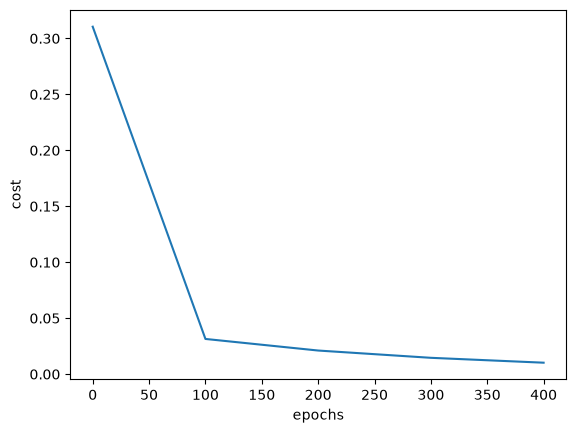

In [13]:
plt.xlabel("epochs")
plt.ylabel("cost")
plt.plot(epochs_list, cost_list)

In [16]:
def predict(area, bedrooms, w, b):
    scaled_X = sx.transform([[area, bedrooms]])
    scaled_price = w[0, 0] * scaled_X[0][0] + w[1, 0] * scaled_X[0][1] + b
    return sy.inverse_transform([[scaled_price]])[0][0]

predict(1600, 2, w, b)

c:\Users\boogey\anaconda3\Lib\site-packages\sklearn\utils\validation.py:2827: UserWarning: X does not have valid feature names, but MinMaxScaler was fitted with feature names
  warnings.warn(


np.float64(305925.70962066745)

In [18]:
import random
random.randint(0, 10)

1

In [ ]:
def stochastic_gradient_descent(X, y_true, epochs, learning_rate=0.01):
    number_of_features = X.shape[1]
    w_sgd = np.ones((number_of_features, 1))
    b_sgd = 0.0
    cost_list_sgd = []
    epochs_list_sgd = []

    for epoch in range(epochs):
        for index in np.random.permutation(X.shape[0]):
            x_sample = X[index:index + 1]
            y_sample = y_true[index:index + 1]

            error = np.dot(x_sample, w_sgd) + b_sgd - y_sample
            w_sgd -= learning_rate * 2 * np.dot(x_sample.T, error)
            b_sgd -= learning_rate * 2 * error.item()

        if epoch % 100 == 0:
            predictions = np.dot(X, w_sgd) + b_sgd
            cost_list_sgd.append(np.mean((y_true - predictions) ** 2))
            epochs_list_sgd.append(epoch)

    return w_sgd, b_sgd, cost_list_sgd, epochs_list_sgd


w_sgd, b_sgd, cost_list_sgd, epochs_list_sgd = stochastic_gradient_descent(
    scaled_X, scaled_y, epochs=500
)

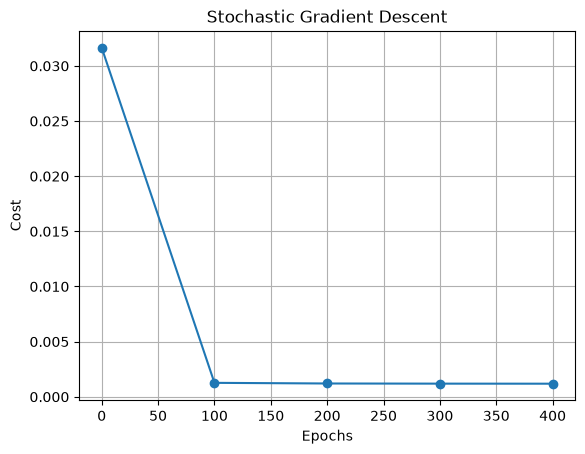

In [ ]:
plt.plot(epochs_list_sgd, cost_list_sgd, marker="o")
plt.xlabel("Epochs")
plt.ylabel("Cost")
plt.title("Stochastic Gradient Descent")
plt.grid(True)
plt.show()

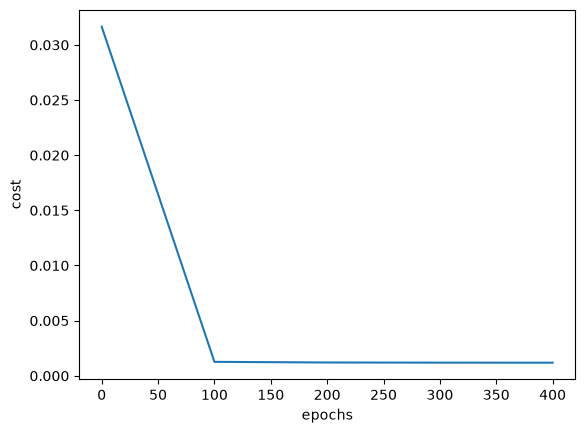

In [39]:
plt.xlabel("epochs")
plt.ylabel("cost")
plt.plot(epochs_list_sgd, cost_list_sgd)